In [1]:
# Temel veri işleme ve analiz için gerekli kütüphaneler
import numpy as np   # Sayısal işlemler ve veri manipülasyonu için
import pandas as pd  # Veri analizi ve veri yapıları için

# Grafikler ve veri görselleştirme için gerekli kütüphaneler
import matplotlib.pyplot as plt  # 2D grafikler çizmek için
import seaborn as sns            # İstatistiksel veri görselleştirme için

# Pandas'ın görüntüleme seçeneklerini ayarlamak için
pd.set_option("display.max_columns", None)  # Tüm sütunların görüntülenmesi için
pd.set_option("display.max_rows", None)     # Tüm satırların görüntülenmesi için

# Uyarıları görmezden gelmek için
import warnings
warnings.filterwarnings("ignore")

# Jupyter Notebooks'ta görüntü eklemek için
from IPython.display import Image

# Seaborn ayarları
sns.set(style="darkgrid", palette="pastel", color_codes=True)  # Seaborn grafik ayarları
sns.set_context("paper")  # Seaborn grafik boyutlarını kağıt formatında ayarlamak için

# Tarih ve zaman işlemleri için
from datetime import datetime

# Plotly kütüphanesi ile gelişmiş veri görselleştirme
import plotly.graph_objects as go  # Grafik nesneleri oluşturmak için
import plotly.express as px        # Hızlı ve kolay veri görselleştirme için
import plotly.io as pio            # Plotly ayarlarını yapmak için
pio.templates.default = "seaborn"  # Varsayılan Plotly şablonunu ayarlamak için

# Alt grafikler oluşturmak için Plotly kütüphanesi
from plotly.subplots import make_subplots

In [2]:
# 'parse_dates' parametresi ile 'Date' sütununu datetime formatında parse çeviriyoruz.
# Bu, tarih ve saat verileriyle ilgili işlemleri kolaylaştırır.
df = pd.read_csv("C:/Users/defne/Desktop/220710017_220710071/covid_19_clean_complete.csv", parse_dates=['Date'])

# İlk 5 satırı görüntüleyerek veri çerçevesinin genel yapısını incelemek için
df.head()

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa


In [3]:
# Veri çerçevesindeki tüm sütun isimlerini görüntüler.
df.columns

Index(['Province/State', 'Country/Region', 'Lat', 'Long', 'Date', 'Confirmed',
       'Deaths', 'Recovered', 'Active', 'WHO Region'],
      dtype='object')

# 1.Sütunlar Hakkında Ayrıntılar:

In [4]:
# Veri çerçevesi hakkında genel bilgi verir.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49068 entries, 0 to 49067
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Province/State  14664 non-null  object        
 1   Country/Region  49068 non-null  object        
 2   Lat             49068 non-null  float64       
 3   Long            49068 non-null  float64       
 4   Date            49068 non-null  datetime64[ns]
 5   Confirmed       49068 non-null  int64         
 6   Deaths          49068 non-null  int64         
 7   Recovered       49068 non-null  int64         
 8   Active          49068 non-null  int64         
 9   WHO Region      49068 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(4), object(3)
memory usage: 3.7+ MB


##### 6 tane sayısal sütun(Lat(Enlem),Long(Boylam),Confirmed(Onaylanmış),Deaths(Ölümler),Recovered(İyileşenler),Active(Aktif)),
##### 2 tane kategorik sütun(Province/State(Vilayet/Durum),Country/Region(Ülke/Bölge)),
##### 1 tane de tarih saat sütunu(Date(Tarih)) vardır.

In [5]:
# Sadece 'object' veri türüne sahip sütunlar için özet istatistikleri gösterir
df.describe(include='object')

,Province/State,Country/Region,WHO Region
count,14664,49068,49068
unique,78,187,6
top,Australian Capital Territory,China,Europe
freq,188,6204,15040


##### Ayrıntılı olarak bakacak olursak veri setinde 187 tane ülke,78 tane vilayet bulunmaktadır.

In [6]:
# Tarih değerlerinin sayımını yap ve tarih sırasına göre sıralar.
a = df.Date.value_counts().sort_index()

# İlk tarihi ekrana yazdırır.
print('The first date is:', a.index[0])

# Son tarihi ekrana yazdırır.
print('The last date is:', a.index[-1])

The first date is: 2020-01-22 00:00:00
The last date is: 2020-07-27 00:00:00


##### Veri seti 22 Ocak 2020-27 Temmuz 2020 arasındaki verileri kapsar.

In [7]:
# DataFrame'deki her sütundaki eksik (NaN) değerlerin sayısını hesaplar
df.isnull().sum()

Province/State    34404
Country/Region        0
Lat                   0
Long                  0
Date                  0
Confirmed             0
Deaths                0
Recovered             0
Active                0
WHO Region            0
dtype: int64

##### Şimdi verileri temizliyeceğiz.

In [8]:
# DataFrame'deki sütunları daha kolay kullanabilmek için yeniden adlandırır.
df.rename(columns={'Date': 'date', 
                     'Province/State':'state',
                     'Country/Region':'country',
                     'Lat':'lat', 'Long':'long',
                     'Confirmed': 'confirmed',
                     'Deaths':'deaths',
                     'Recovered':'recovered'
                    }, inplace=True)

# Aktif Vaka = onaylanmış vakalar - ölümler - iyileşenler
df['active'] = df['confirmed'] - df['deaths'] - df['recovered']

# 2.Plotly Kullanarak Görselleştirme

##### Veri görselleştirme, veri madenciliğinin temel becerilerinden biridir. Modelleri oluşturmaya başlamadan önce, temel veri setini anlamamız gerekir. Çalıştığımız veri konusunda hiçbir zaman tam anlamıyla uzman olamayız ve bir model oluşturmaya veya veri ile başka bir şey yapmaya başlamadan önce, değişkenleri derinlemesine keşfetmeniz ve anlamamız gerekecektir. Etkili veri görselleştirme, bu süreci gerçekleştirmek için en önemli araçtır ve bu yüzden ustalaşmamız gereken kritik bir beceridir.

##### Bunun için, Plotly Python Açık Kaynak Grafik Kütüphanesi'ni kullandık. Plotly, coğrafi, bilimsel, istatistiksel ve finansal verileri işleyebilen bir Python görselleştirme aracıdır. Plotly'nin Matplotlib'e göre birçok avantajı vardır. Ana avantajlarından biri, estetik açıdan hoş ve etkileşimli grafikler oluşturmak için sadece birkaç satır kodun yeterli olmasıdır. Ayrıca statik Matplotlib grafiklerine göre birçok avantaj sunar:

#####    1) Veri setini başlangıçta keşfederken zaman kazandırır.
#####    2) Grafikleri kolayca değiştirmeyi ve dışa aktarmayı sağlar.
#####    3) Veri setindeki önemli kısımları aktarmak için uygun ve süslü bir görselleştirme sunar.

##### Plotly harita görselleştirmelerinin farklı türlerini kullanarak örnekleri göstermeye çalıştık.

## A.Dünya Çapında Yayılma Analizi

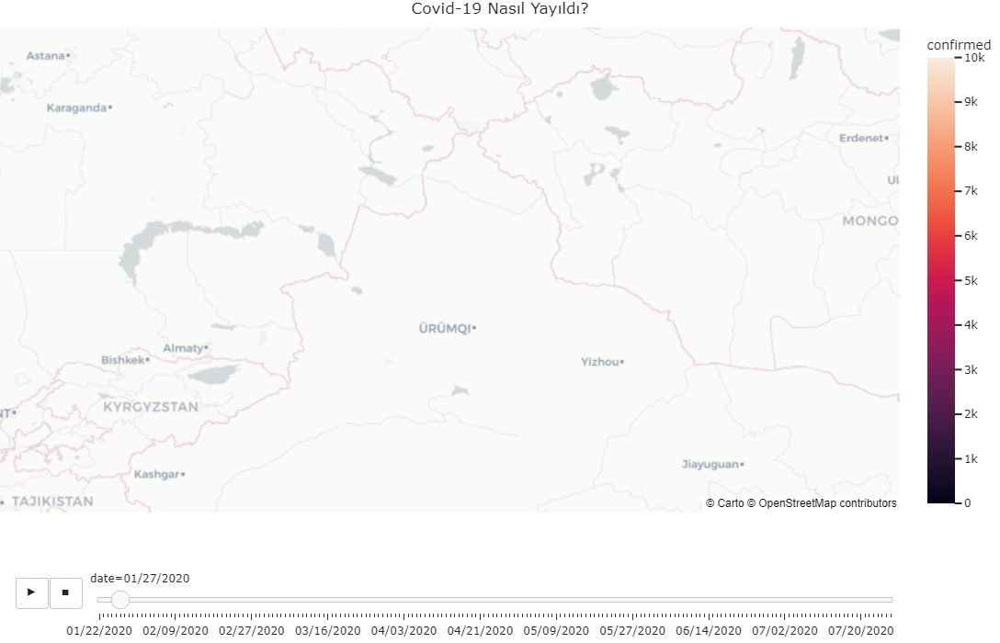

In [18]:
# Yeni bir DataFrame oluşturarak 'df' veri çerçevesini kopyalıyoruz.
df1 = df

# 'date' sütununu datetime veri türüne dönüştürüyoruz.
df1['date'] = pd.to_datetime(df1['date'])

# 'date' sütununu 'mm/dd/yyyy' formatına dönüştürüyoruz.
df1['date'] = df1['date'].dt.strftime('%m/%d/%Y')

# Eksik değerleri '-' ile dolduruyoruz.
df1 = df1.fillna('-')

# Plotly kütüphanesini kullanarak yoğunluk haritası oluşturuyoruz.
fig = px.density_mapbox(df1, lat='lat', lon='long', z='confirmed', radius=20, zoom=1,
                        hover_data=["country", 'state', "confirmed"], mapbox_style="carto-positron",
                        animation_frame='date', range_color=[0, 10000],
                        title='Covid-19 Nasıl Yayıldı?')

# Harita düzenini güncelliyoruz.
fig.update_layout(
    margin={"r": 0, "t": 30, "l": 0, "b": 0},  # Kenar boşluklarını ayarlıyoruz.
    height=700,  # Haritanın yüksekliğini ayarlıyoruz.
    width=1000   # Haritanın genişliğini ayarlıyoruz.
)

# Haritayı gösteriyoruz.
fig.show()

##### Gözlemlerimiz:
##### 1)Virüsün yayılması başlangıçta yavaş ve sayılar da düşük.
##### 2)Zaman geçtikçe, yayılma hızlanmış ve sayılar kontrolsüz bir şekilde artmış.
##### 3)Koruyucu önlemler alınmazsa, hızlanma devam eder ve önüne geçilemez bir hal alır.

## B.Dünya Genelinde Aktif Vakalar

In [24]:
# En son tarihe sahip girişleri seçer ve en güncel verilere ulaşmayı amaçlar.
top = df[df['date'] == df['date'].max()]

# Her ülkenin toplam onaylanmış, aktif ve ölüm vakalarını gruplar ve toplar.
world = top.groupby('country')[['confirmed','active','deaths']].sum().reset_index()

# İlk beş girişi göster.
world.head()

,country,confirmed,active,deaths
0,Afghanistan,36263,9796,1269
1,Albania,4880,1991,144
2,Algeria,27973,7973,1163
3,Andorra,907,52,52
4,Angola,950,667,41


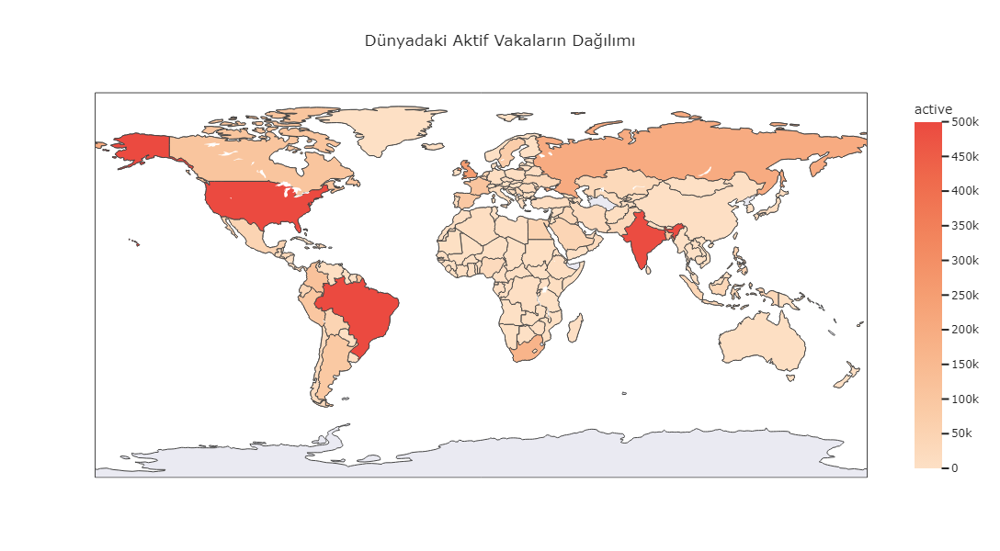

In [28]:
# Veri kaynağımızı oluşturuyoruz.
world = top.groupby('country')[['confirmed','active','deaths']].sum().reset_index()

# px.choropleth fonksiyonunu kullanarak choropleth haritasını oluşturuyoruz.
figure = px.choropleth(world, 
                       locations="country",  # Renklendirilecek konumu belirtiyoruz (ülke adları).
                       locationmode='country names',  # Konum modunu ülke adları olarak belirtiyoruz.
                       color="active",  # Renklendirmenin aktif vaka sayısına göre yapılacağını belirtiyoruz.
                       hover_name="country",  # Fareyi bir ülkenin üzerine getirdiğimizde gösterilecek bilgiyi belirtiyoruz (ülke adları).
                       range_color=[1,500000],  # Renk aralığını belirtiyoruz (en düşük ve en yüksek aktif vaka sayıları).
                       color_continuous_scale="Peach",  # Renk skalasını belirtiyoruz (Peach adlı önceden Plotly tarafından tanımlanmış renk skalası).
                       title='Dünyadaki Aktif Vakaların Dağılımı'  # Haritanın başlığını belirtiyoruz.
                      )
figure.update_layout(
     height=600,  # Haritanın yüksekliğini piksel cinsinden belirtiyoruz.
    width=800    # Haritanın genişliğini piksel cinsinden belirtiyoruz.  
)
# Oluşturulan choropleth haritasını görüntülüyoruz.
figure.show()

##### Gözlemlerimiz:
##### 1) Çoğu ülke 10.000 engelini aşmış durumda, bazıları ise virüsün yayılmasını kontrol altına almayı başarmış ve 10.000'in altında tutmuş.
##### 2) Çin, aktif vaka sayısını azaltan ülkelerden birisi.
##### 3) Ancak ABD, İtalya, Türkiye, İspanya, Fransa, Hindistan gibi diğer bazı ülkelerde aktif vaka sayısı hızla artıyor.

## C.Dünya Genelinde İyileşenlerin Sayısı

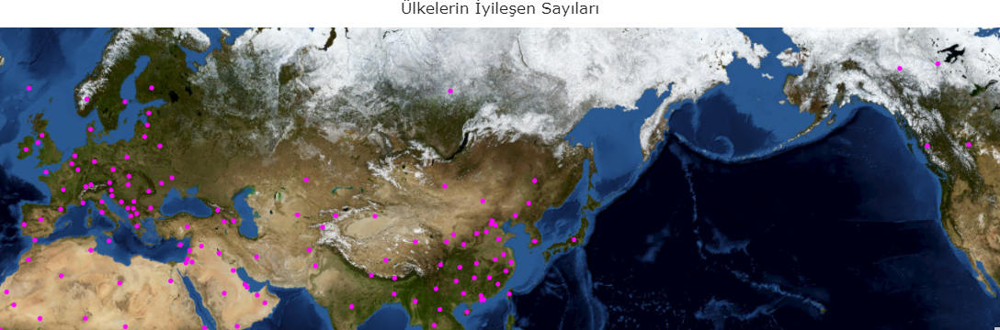

In [31]:
# En son tarihteki verileri içeren 'top' veri çerçevesini kullanarak bir harita oluşturur.
fig = px.scatter_mapbox(top, lat="lat", lon="long", hover_name="country", hover_data=["country","recovered"],
                        color_discrete_sequence=["fuchsia"], zoom=0.5, height=300,title='Ülkelerin İyileşen Sayıları' )

# Harita stilini ve alt katmanlarını belirler.
fig.update_layout(
    mapbox_style="white-bg",
    mapbox_layers=[
        {
            "below": 'traces',
            "sourcetype": "raster",
            "source": [
                "https://basemap.nationalmap.gov/arcgis/rest/services/USGSImageryOnly/MapServer/tile/{z}/{y}/{x}"
            ]
        }
      ])

# Haritanın kenar boşluklarını ayarlar.
fig.update_layout(margin={"r":0,"t":30,"l":0,"b":0})

# Haritayı gösterir.
fig.show()

## D.Dünya Genelinde Ölüm Sayısı

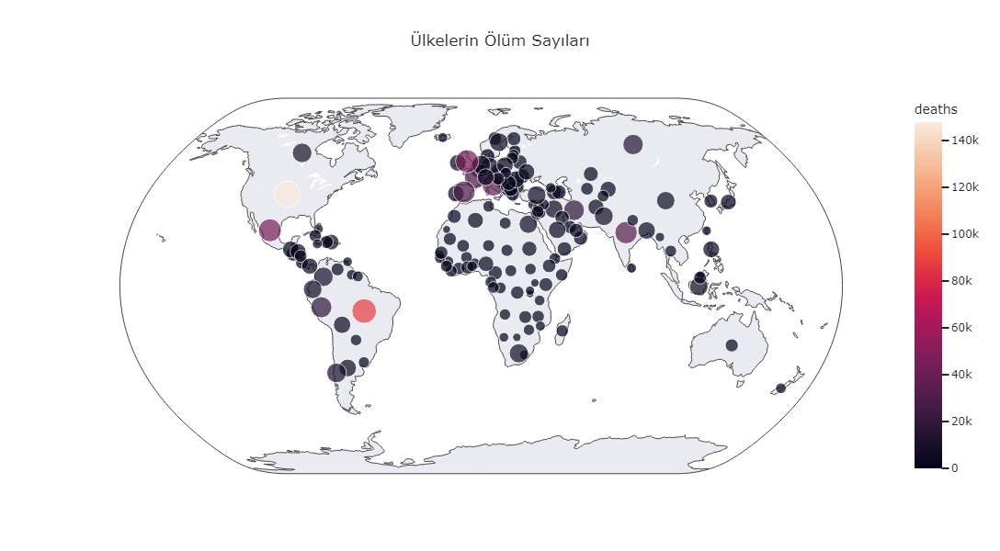

In [39]:
# Her bir ülkenin ölüm sayısını kullanarak 'size' sütununu oluşturuyoruz.
world['size'] = world['deaths'].pow(0.2)

# Plotly Express kullanılarak scatter_geo grafiği oluşturuyoruz.
fig = px.scatter_geo(world, 
                     locations="country",        # Ülkelerin konumunu belirtir.
                     locationmode='country names',  # Konum modunu belirtir; burada ülke adları kullanılır.
                     color="deaths",            # Renk kodunu belirtir; burada ölüm sayısını kullanır
                     hover_name="country",      # Fare imlecini bir ülkenin üzerine getirdiğinizde gösterilecek metni belirtir; burada ülke adları kullanılır.
                     size="size",               # Noktaların boyutunu belirtir; burada 'size' sütununu kullanır.
                     hover_data=['country', 'deaths'],  # Fare imlecini bir ülkenin üzerine getirdiğinizde gösterilecek ek veriyi belirtir; burada ülke adı ve ölüm sayısı kullanılır.
                     projection="natural earth",   # Harita projeksiyonunu belirtir; burada doğal Dünya haritası kullanılır.
                     title='Ülkelerin Ölüm Sayıları'  # Grafik başlığını belirtir.
                    )

# Grafik düzenini ayarlıyoruz.
fig.update_layout(
    geo=dict(
        scope='world'   # Harita kapsamını belirtir; burada dünya haritasını kullanır.
    ),
    width=800,           # Haritanın genişliğini belirtir.
    height=600           # Haritanın yüksekliğini belirtir.
)

# Oluşturulan grafiği görüntülüyoruz.
fig.show()

# 3.Seaborn Kullanarak Görselleştirme

## A.Zaman İçinde Onaylanan Vakalar

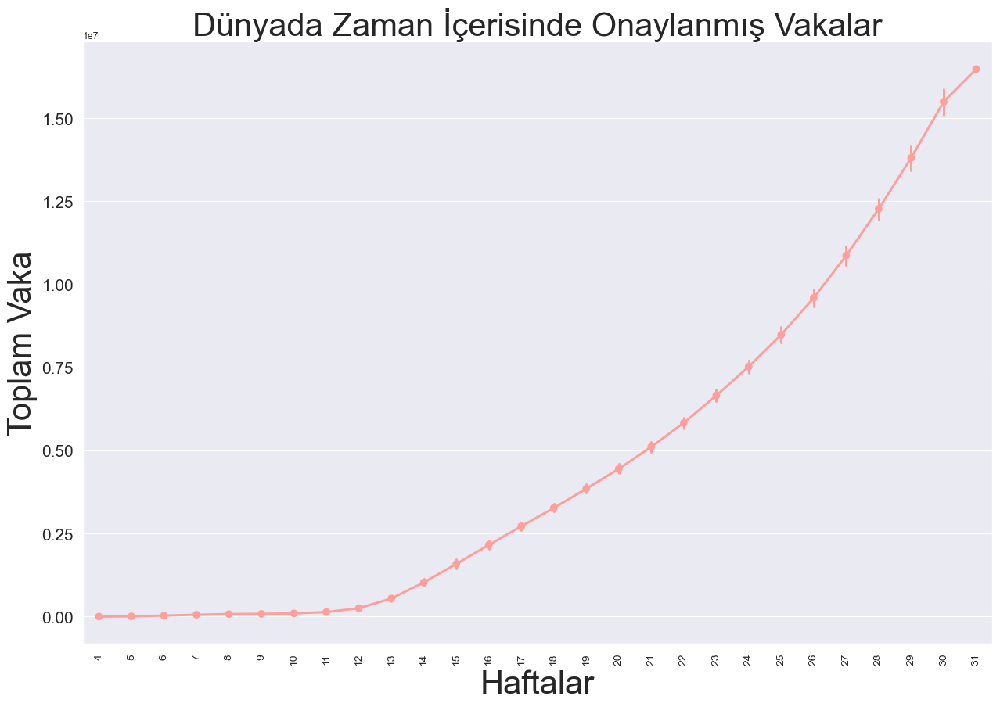

In [15]:
# Bu komut, matplotlib'te bir figür oluşturarak çizim boyutunu belirler.
plt.figure(figsize=(15, 10))

# x eksenindeki etiketlerin dikey yönde 90 derece döndürülmesini sağlar ve font boyutunu ayarlar.
plt.xticks(rotation=90, fontsize=10)

# y eksenindeki etiketlerin font boyutunu ayarlar.
plt.yticks(fontsize=15)

# x eksenine etiket ekler ve font boyutunu ayarlar.
plt.xlabel("Tarihler", fontsize=30)

# y eksenine etiket ekler ve font boyutunu ayarlar.
plt.ylabel('Toplam vakalar', fontsize=30)

# Grafiğin başlığını ekler ve font boyutunu ayarlar.
plt.title("Dünyada Zaman İçerisinde Onaylanmış Vakalar", fontsize=30)

# Veri kümesini 'date' sütununa göre gruplayarak her günün toplam onaylanmış vakasını hesaplar.
total_cases = df.groupby('date')['confirmed'].sum().reset_index()

# 'date' sütununu zaman damgasına dönüştürür.
total_cases['date'] = pd.to_datetime(total_cases['date'])

# seaborn kütüphanesini kullanarak nokta grafiği çizer.
# x eksenine haftanın sayısını, y eksenine toplam onaylanmış vakaları alır.
# Grafiğin rengini kırmızı ('r') olarak ayarlar.
ax = sns.pointplot(x=total_cases['date'].dt.isocalendar().week, y=total_cases['confirmed'], color='r')

# Eksenlere etiketler ekler.
ax.set(xlabel='Haftalar', ylabel='Toplam Vaka')

# Grafiği gösterir.
plt.show()

##### Gözlemlerimiz:
##### 1)Çizginin eğimi başlangıçta yavaş yavaş yükseliyor ancak zamanla hızlanıyor.
##### 2)Mevcut hızda, toplam vakalarda düşüş belirtisi yok.
##### 3)Koruyucu önlemler alınmazsa, eğrinin maksimuma ulaşması olasıdır.

## B.En Çok Doğrulanmış Vakanın Görüldüğü 20 Ülke

In [17]:
# Veri kümesindeki en son tarihe sahip satırları seçer.
top = df[df['date'] == df['date'].max()]

# En yüksek toplam vaka sayısına sahip ilk 20 ülkeyi seçer.
top_casualties = top.groupby(by='country')['confirmed'].sum().sort_values(ascending=False).head(20).reset_index()

# Sonuçları görüntüler.
top_casualties

,country,confirmed
0,US,4290259
1,Brazil,2442375
2,India,1480073
3,Russia,816680
4,South Africa,452529
5,Mexico,395489
6,Peru,389717
7,Chile,347923
8,United Kingdom,301708
9,Iran,293606


[Text(0.5, 0, 'Toplam vakalar'), Text(0, 0.5, 'Ülke')]

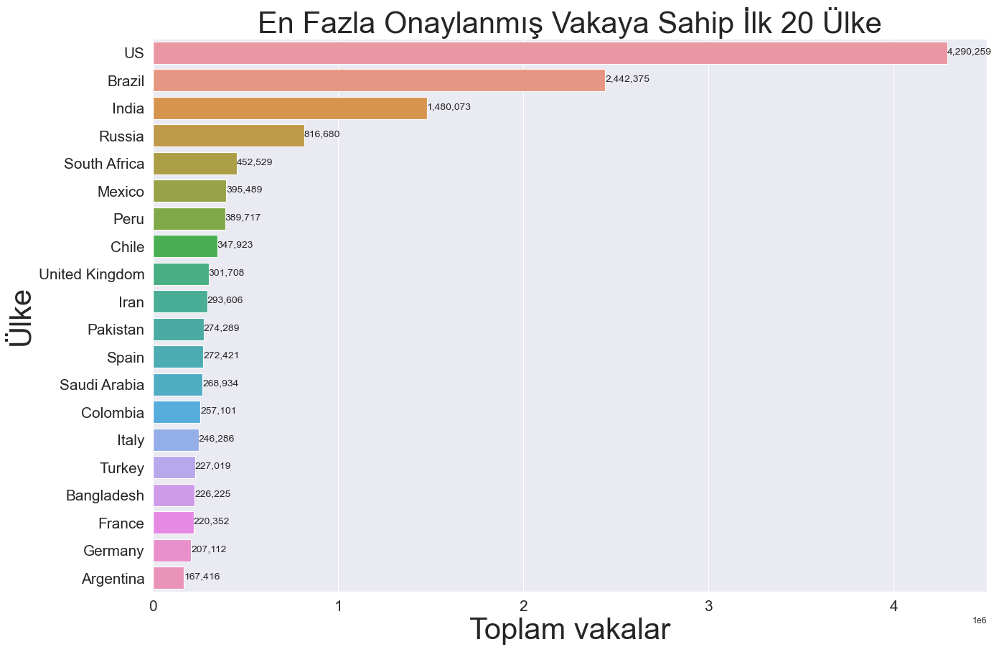

In [20]:
# Yeni bir çizim oluşturarak çizim boyutunu belirler.
plt.figure(figsize=(15, 10))

# x ekseni etiketlerinin font boyutunu ayarlar.
plt.xticks(fontsize=15)

# y ekseni etiketlerinin font boyutunu ayarlar.
plt.yticks(fontsize=15)

# x eksenine etiket ekler ve font boyutunu ayarlar.
plt.xlabel("Toplam vakalar", fontsize=30)

# y eksenine etiket ekler ve font boyutunu ayarlar.
plt.ylabel('Ülke', fontsize=30)

# Grafiğin başlığını ekler ve font boyutunu ayarlar.
plt.title("En Fazla Onaylanmış Vakaya Sahip İlk 20 Ülke", fontsize=30)

# Seaborn kütüphanesini kullanarak bir sütun grafiği (bar plot) çizer.
# x ekseni toplam vakaları, y ekseni ise ülkeleri temsil eder.
ax = sns.barplot(x=top_casualities.confirmed, y=top_casualities.country)

# Her çubuğun üzerine onaylanmış vaka sayısını ekler.
for i, (value, name) in enumerate(zip(top_casualities.confirmed, top_casualities.country)):
    ax.text(value, i - 0.05, f'{value:,.0f}', size=10, ha='left', va='center')

# Eksenlere etiketler ekler.
ax.set(xlabel='Toplam vakalar', ylabel='Ülke')

##### Gözlemlerimiz:
##### 1)Çin başlangıç noktasıydı ama şimdi ilk 20 içinde bile değiller.
##### 2)ABD, Brezilya, Hindistan ve Rusya'nın onaylanmış vaka sayıları en yüksek olanlar.
##### 3)Ancak üçüncü dünya ülkelerinde vaka sayısı daha az.

## B.En Çok Aktif Vakanın Görüldüğü 20 Ülke

In [21]:
# Her bir ülkedeki aktif vakaların toplamını alır ve en yüksek 20 değeri seçer.
top_actives = top.groupby(by='country')['active'].sum().sort_values(ascending=False).head(20).reset_index()

# Sonuçları görüntüler.
top_actives

,country,active
0,US,2816444
1,Brazil,508116
2,India,495499
3,United Kingdom,254427
4,Russia,201097
5,South Africa,170537
6,Colombia,117163
7,France,108928
8,Canada,107514
9,Peru,98752


[Text(0.5, 0, 'Toplam vakalar'), Text(0, 0.5, 'Ülke')]

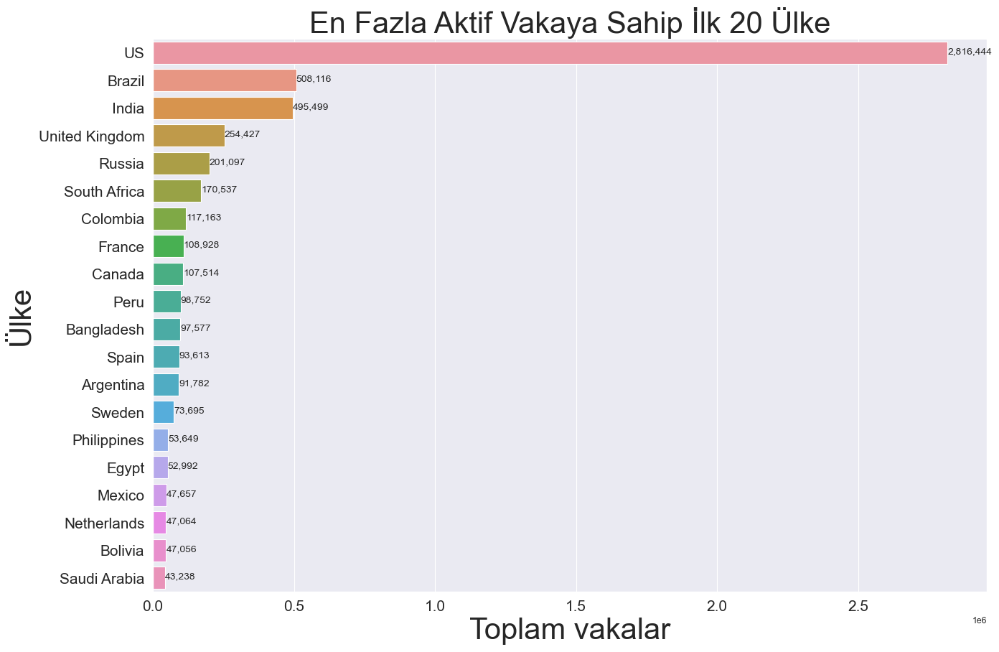

In [22]:
# Yeni bir çizim oluşturarak çizim boyutunu belirler.
plt.figure(figsize=(15, 10))

# x ekseni etiketlerinin font boyutunu ayarlar.
plt.xticks(fontsize=15)

# y ekseni etiketlerinin font boyutunu ayarlar.
plt.yticks(fontsize=15)

# x eksenine etiket ekler ve font boyutunu ayarlar.
plt.xlabel("Toplam vakalar", fontsize=30)

# y eksenine etiket ekler ve font boyutunu ayarlar.
plt.ylabel('Ülke', fontsize=30)

# Grafiğin başlığını ekler ve font boyutunu ayarlar.
plt.title("En Fazla Aktif Vakaya Sahip İlk 20 Ülke", fontsize=30)

# Seaborn kütüphanesini kullanarak bir sütun grafiği (bar plot) çizer.
# x ekseni aktif vakaları, y ekseni ise ülkeleri temsil eder.
ax = sns.barplot(x=top_actives.active, y=top_actives.country)

# Her çubuğun üzerine aktif vaka sayısını ekler.
for i, (value, name) in enumerate(zip(top_actives.active, top_actives.country)):
    ax.text(value, i - 0.05, f'{value:,.0f}', size=10, ha='left', va='center')

# Eksenlere etiketler ekler.
ax.set(xlabel='Toplam vakalar', ylabel='Ülke')

##### Gözlemlerimiz:
##### 1)Covid-19'un test oranı arttıkça aktif vaka sayısı da artıyor.
##### 2)Aktif vaka sayısı ABD, Brezilya, Hindistan ülkelerinde yüksek seviyede.
##### 3)Toplam nüfusa göre karşılaştırıldığında İspanya ve Fransa en kötü etkilenen ülkelerdir.

## D.En Çok Ölümün Yaşandığı 20 Ülke

In [23]:
# Her bir ülkedeki toplam ölüm sayısını alır ve en yüksek 20 değeri seçer.
top_deaths = top.groupby(by='country')['deaths'].sum().sort_values(ascending=False).head(20).reset_index()

# Sonuçları görüntüler.
top_deaths

,country,deaths
0,US,148011
1,Brazil,87618
2,United Kingdom,45844
3,Mexico,44022
4,Italy,35112
5,India,33408
6,France,30212
7,Spain,28432
8,Peru,18418
9,Iran,15912


[Text(0.5, 0, 'Toplam vakalar'), Text(0, 0.5, 'Ülke')]

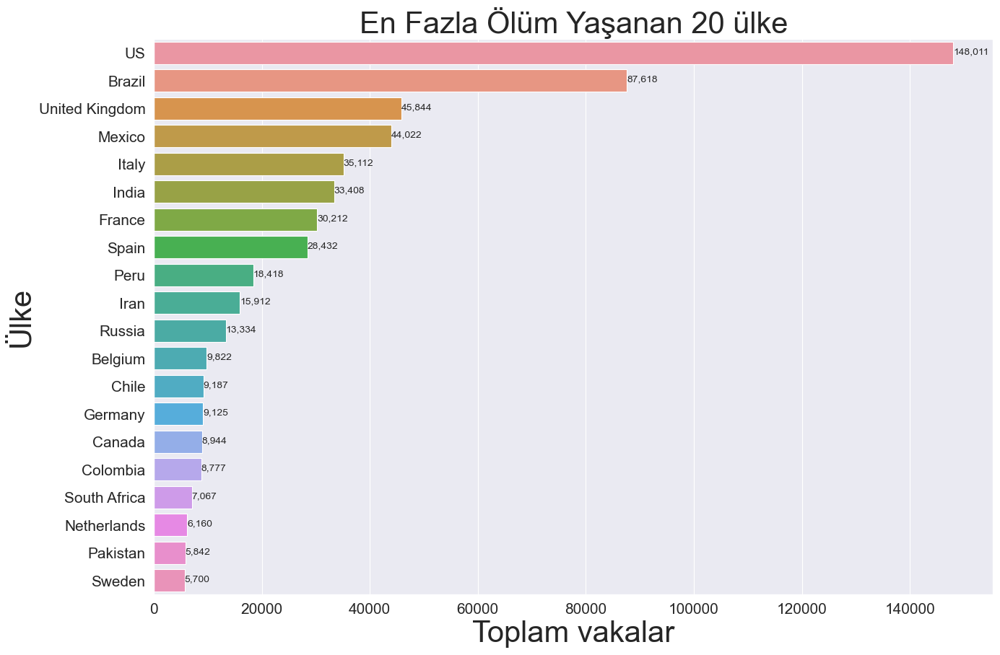

In [25]:
# Yeni bir çizim oluşturarak çizim boyutunu belirler.
plt.figure(figsize=(15, 10))

# x ekseni etiketlerinin font boyutunu ayarlar.
plt.xticks(fontsize=15)

# y ekseni etiketlerinin font boyutunu ayarlar.
plt.yticks(fontsize=15)

# x eksenine etiket ekler ve font boyutunu ayarlar.
plt.xlabel("Toplam vakalar", fontsize=30)

# y eksenine etiket ekler ve font boyutunu ayarlar.
plt.ylabel('Ülke', fontsize=30)

# Grafiğin başlığını ekler ve font boyutunu ayarlar.
plt.title("En Fazla Ölüm Yaşanan 20 ülke", fontsize=30)

# Seaborn kütüphanesini kullanarak bir sütun grafiği (bar plot) çizer.
# x ekseni ölüm sayılarını, y ekseni ise ülkeleri temsil eder.
ax = sns.barplot(x=top_deaths.deaths, y=top_deaths.country)

# Her çubuğun üzerine ölüm sayısını ekler.
for i, (value, name) in enumerate(zip(top_deaths.deaths, top_deaths.country)):
    ax.text(value, i - 0.05, f'{value:,.0f}', size=10, ha='left', va='center')

# Eksenlere etiketler ekler.
ax.set(xlabel='Toplam vakalar', ylabel='Ülke')

##### Gözlemlerimiz:
##### 1)İtalya, Dünya Sağlık Örgütü'ne göre 2. en iyi sağlık sistemine sahip olmasına rağmen, pandemi sorununu etkili bir şekilde ele alamamıştır.
##### 2)Çin'de çok onaylanmış vaka sayısının fazla olmasına rağmen ölüm sayısını azaltmayı başarmıştır.
##### 3)Ölüm sayısı hızla artıyor, özellikle İtalya, İspanya ve İran'da.

## E.En Çok İyileşen Vakanın Görüldüğü 20 Ülke

In [26]:
# Her bir ülkedeki toplam iyileşen sayısını alır ve en yüksek 20 değeri seçer.
top_recovered = top.groupby(by='country')['recovered'].sum().sort_values(ascending=False).head(20).reset_index()

# Sonuçları görüntüler.
top_recovered

,country,recovered
0,Brazil,1846641
1,US,1325804
2,India,951166
3,Russia,602249
4,Chile,319954
5,Mexico,303810
6,South Africa,274925
7,Peru,272547
8,Iran,255144
9,Pakistan,241026


[Text(0.5, 0, 'Toplam vakalar'), Text(0, 0.5, 'Ülke')]

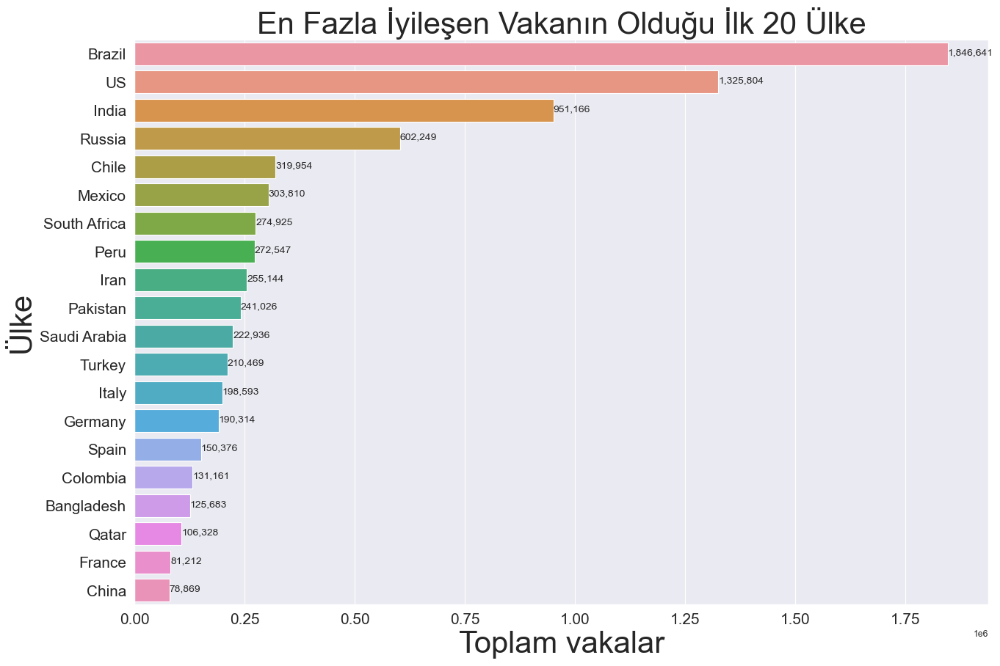

In [27]:
# Yeni bir çizim oluşturarak çizim boyutunu belirler.
plt.figure(figsize=(15, 10))

# x ekseni etiketlerinin font boyutunu ayarlar.
plt.xticks(fontsize=15)

# y ekseni etiketlerinin font boyutunu ayarlar.
plt.yticks(fontsize=15)

# x eksenine etiket ekler ve font boyutunu ayarlar.
plt.xlabel("Toplam vakalar", fontsize=30)

# y eksenine etiket ekler ve font boyutunu ayarlar.
plt.ylabel('Ülke', fontsize=30)

# Grafiğin başlığını ekler ve font boyutunu ayarlar.
plt.title("En Fazla İyileşen Vakanın Olduğu İlk 20 Ülke", fontsize=30)

# Seaborn kütüphanesini kullanarak bir sütun grafiği (bar plot) çizer.
# x ekseni iyileşen vakaları, y ekseni ise ülkeleri temsil eder.
ax = sns.barplot(x=top_recovered.recovered, y=top_recovered.country)

# Her çubuğun üzerine iyileşen vaka sayısını ekler.
for i, (value, name) in enumerate(zip(top_recovered.recovered, top_recovered.country)):
    ax.text(value, i - 0.05, f'{value:,.0f}', size=10, ha='left', va='center')

# Eksenlere etiketler ekler.
ax.set(xlabel='Toplam vakalar', ylabel='Ülke')

##### Gözlemlerimiz:
##### 1)Brezilya çok sayıda onaylanmış vaka olmasına rağmen, en fazla iyileşme sayısına sahip.
##### 2)İtalya, İran,İspanya ve Türkiye'nin oranları da iyi.
##### 3)İyileşen sayıları hızla artan bir ivme kazanmalı.

## F.En Kötü Ölüm Oranına Ve En İyi İyileşme Oranına Sahip İlk 20 Ülke

In [29]:
# Her bir ülkenin toplam iyileşen, onaylanmış vaka ve ölüm sayılarını toplar.
rate = top.groupby(by='country')[['recovered', 'confirmed', 'deaths']].sum().reset_index()

# İyileşme oranını hesaplar ve 'recovery percentage' sütununa ekler.
rate['recovery percentage'] = round((rate['recovered'] / rate['confirmed']) * 100, 2)

# Ölüm oranını hesaplar ve 'death percentage' sütununa ekler.
rate['death percentage'] = round((rate['deaths'] / rate['confirmed']) * 100, 2)

# İlk 5 satırı görüntüler.
rate.head()

,country,recovered,confirmed,deaths,recovery percentage,death percentage
0,Afghanistan,25198,36263,1269,69.49,3.50
1,Albania,2745,4880,144,56.25,2.95
2,Algeria,18837,27973,1163,67.34,4.16
3,Andorra,803,907,52,88.53,5.73
4,Angola,242,950,41,25.47,4.32


In [30]:
# Her bir ülkenin ölüm oranını toplar ve en yüksek 20 değeri seçer.
mortality = rate.groupby(by='country')['death percentage'].sum().sort_values(ascending=False).head(20).reset_index()

# Sonuçları görüntüler.
mortality

,country,death percentage
0,Yemen,28.56
1,United Kingdom,15.19
2,Belgium,14.79
3,Italy,14.26
4,France,13.71
5,Hungary,13.40
6,Netherlands,11.53
7,Mexico,11.13
8,Spain,10.44
9,Western Sahara,10.00


[Text(0.5, 0, 'Ölüm Oranı'), Text(0, 0.5, 'Ülke')]

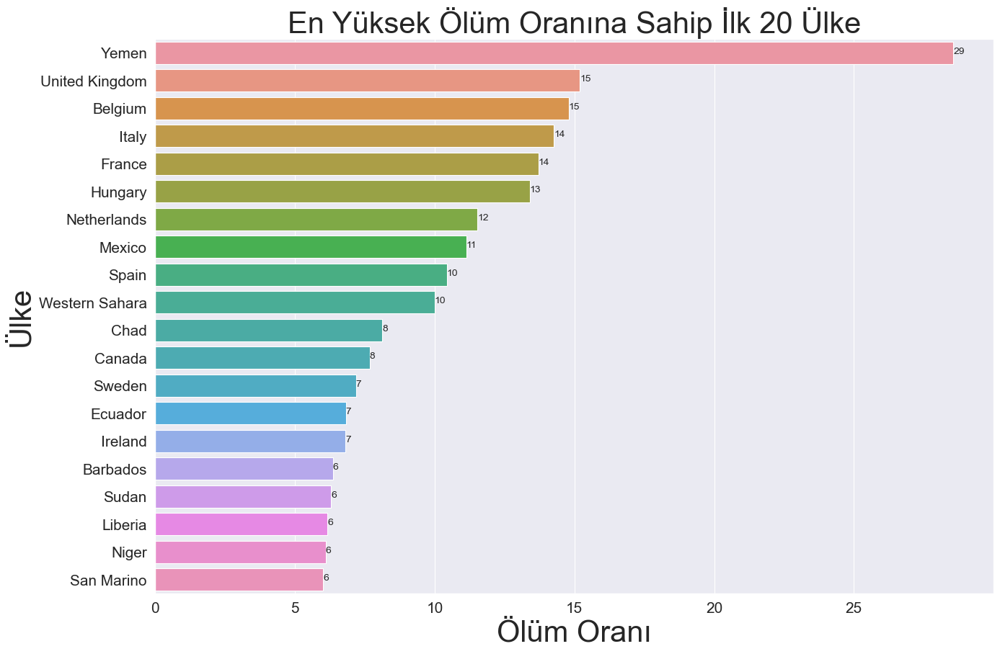

In [33]:
# Yeni bir çizim oluşturarak çizim boyutunu belirler.
plt.figure(figsize=(15, 10))

# x ekseni etiketlerinin font boyutunu ayarlar.
plt.xticks(fontsize=15)

# y ekseni etiketlerinin font boyutunu ayarlar.
plt.yticks(fontsize=15)

# x eksenine etiket ekler ve font boyutunu ayarlar.
plt.xlabel("Toplam vakalar", fontsize=30)

# y eksenine etiket ekler ve font boyutunu ayarlar.
plt.ylabel('Ülke', fontsize=30)

# Grafiğin başlığını ekler ve font boyutunu ayarlar.
plt.title("En Yüksek Ölüm Oranına Sahip İlk 20 Ülke", fontsize=30)

# Seaborn kütüphanesini kullanarak bir sütun grafiği (bar plot) çizer.
# x ekseni ölüm oranlarını, y ekseni ise ülkeleri temsil eder.
ax = sns.barplot(x=mortality['death percentage'], y=mortality.country)

# Her çubuğun üzerine ölüm oranını ekler.
for i, (value, name) in enumerate(zip(mortality['death percentage'], mortality.country)):
    ax.text(value, i - 0.05, f'{value:,.0f}', size=10, ha='left', va='center')

# Eksenlere etiketler ekler.
ax.set(xlabel='Ölüm Oranı', ylabel='Ülke')

##### Gözlemlerimiz:
##### 1)Listede başı çeken ülkelerin çoğu kötü bir sağlık sistemine sahip ve gelişmiş ülkelerden yardım almaları gerekmektedir.
##### 2)En az 100 onaylanmış vaka dikkate alındığında, San Marino, Irak ve Endonezya listede ilk sırayı alıyor.
##### 3)200.000'den fazla onaylanmış vakaya sahip İtalya en üst sırada, bu yüzde oranı oldukça korkutucu. Covid-19'un yayılmasında kontrolü kaybetmiş gibi görünüyorlar ve bunu kontrol altına alamıyorlar.

In [34]:
# Her bir ülkenin iyileşme yüzdesini toplar ve en yüksek 20 değeri seçer.
recovery = rate.groupby(by='country')['recovery percentage'].sum().sort_values(ascending=False).head(20).reset_index()

# Sonuçları görüntüler.
recovery

,country,recovery percentage
0,Holy See,100.00
1,Grenada,100.00
2,Dominica,100.00
3,Djibouti,98.38
4,Iceland,98.33
5,Brunei,97.87
6,New Zealand,97.24
7,Qatar,97.02
8,Malaysia,96.60
9,Mauritius,96.51


[Text(0.5, 0, 'İyileşme Oranı'), Text(0, 0.5, 'Ülke')]

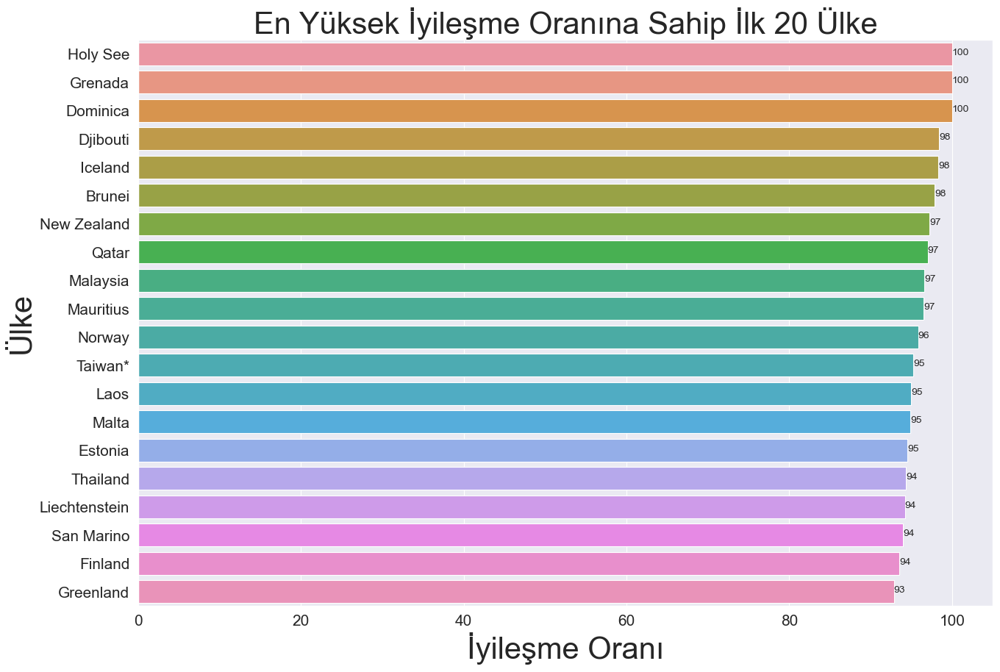

In [35]:
# Yeni bir çizim oluşturarak çizim boyutunu belirler.
plt.figure(figsize=(15, 10))

# x ekseni etiketlerinin font boyutunu ayarlar.
plt.xticks(fontsize=15)

# y ekseni etiketlerinin font boyutunu ayarlar.
plt.yticks(fontsize=15)

# x eksenine etiket ekler ve font boyutunu ayarlar.
plt.xlabel("Toplam vakalar", fontsize=30)

# y eksenine etiket ekler ve font boyutunu ayarlar.
plt.ylabel('Ülke', fontsize=30)

# Grafiğin başlığını ekler ve font boyutunu ayarlar.
plt.title("En Yüksek İyileşme Oranına Sahip İlk 20 Ülke", fontsize=30)

# Seaborn kütüphanesini kullanarak bir sütun grafiği (bar plot) çizer.
# x ekseni iyileşme oranlarını, y ekseni ise ülkeleri temsil eder.
ax = sns.barplot(x=recovery['recovery percentage'], y=recovery.country)

# Her çubuğun üzerine iyileşme oranını ekler.
for i, (value, name) in enumerate(zip(recovery['recovery percentage'], recovery.country)):
    ax.text(value, i - 0.05, f'{value:,.0f}', size=10, ha='left', va='center')

# Eksenlere etiketler ekler.
ax.set(xlabel='İyileşme Oranı', ylabel='Ülke')

##### Gözlemlerimiz:
##### 1)Holy See,Grenada ve Dominik her onaylanmış vakayı iyileştiriyor.
##### 2)İyileşme oranının nüfus ile ters orantılı olduğunu söyleyebiliriz.

# 3.En Çok Etkilenen Ülkelerin Analizi

##### Analiz ve görselleştirmeler sonucunda en çok etkilenen ülkeleri seçtik; yani Çin, ABD, İtalya. Ayrıca Türkiye'yi de seçtik, böylece ülkemizdeki Covid-19 sorununu analiz edebiliriz.

In [40]:
# 'country' sütunu 'China' olan satırları seçiyoruz.
china = df[df['country'] == 'China']

# Tarih bazında iyileşen, ölüm, onaylanmış vaka ve aktif vaka sayılarını gruplayarak topluyoruz.
china = china.groupby(by='date')[['recovered', 'deaths', 'confirmed', 'active']].sum().reset_index()

# 'date' sütununu pandas'ın to_datetime fonksiyonuyla datetime nesnesine dönüştürüyoruz.
china['date'] = pd.to_datetime(china['date'])

# İlk 5 satırı görüntülüyoruz.
china.head()

,date,recovered,deaths,confirmed,active
0,2020-01-22,28,17,548,503
1,2020-01-23,30,18,643,595
2,2020-01-24,36,26,920,858
3,2020-01-25,39,42,1406,1325
4,2020-01-26,49,56,2075,1970


In [42]:
# 'country' sütunu 'US' olan satırları seçiyoruz.
us = df[df['country'] == 'US']

# Tarih bazında iyileşen, ölüm, onaylanmış vaka ve aktif vaka sayılarını gruplayarak topluyoruz.
us = us.groupby(by='date')[['recovered', 'deaths', 'confirmed', 'active']].sum().reset_index()

# Veriyi 33. satırdan itibaren alıyoruz (US'teki ilk Covid-19 vakasının tarihi 22 Ocak 2020 olduğu için).
us = us.iloc[33:].reset_index().drop('index', axis=1)

# İlk 5 satırı görüntülüyoruz.
us.head()

,date,recovered,deaths,confirmed,active
0,2020-02-24,5,0,15,10
1,2020-02-25,6,0,15,9
2,2020-02-26,6,0,15,9
3,2020-02-27,6,0,16,10
4,2020-02-28,7,0,16,9


In [48]:
# 'country' sütunu 'Italy' olan satırları seçiyoruz.
italy = df[df['country'] == 'Italy']

# Tarih bazında iyileşen, ölüm, onaylanmış vaka ve aktif vaka sayılarını gruplayarak topluyoruz.
italy = italy.groupby(by='date')[['recovered', 'deaths', 'confirmed', 'active']].sum().reset_index()

# Veriyi '2020-01-31' tarihinden itibaren alıyoruz.
italy = italy[italy['date'] >= '2020-01-31']

# İlk 5 satırı görüntülüyoruz.
italy.head()

,date,recovered,deaths,confirmed,active
9,2020-01-31,0,0,2,2
10,2020-02-01,0,0,2,2
11,2020-02-02,0,0,2,2
12,2020-02-03,0,0,2,2
13,2020-02-04,0,0,2,2


In [49]:
# 'country' sütunu 'Turkey' olan satırları seçiyoruz.
turkey = df[df['country'] == 'Turkey']

# Tarih bazında iyileşen, ölüm, onaylanmış vaka ve aktif vaka sayılarını gruplayarak topluyoruz.
turkey = turkey.groupby(by='date')[['recovered', 'deaths', 'confirmed', 'active']].sum().reset_index()

# Veriyi '2020-03-11' tarihinden itibaren alıyoruz (Türkiye'deki ilk Covid-19 vakasının tarihi).
turkey = turkey[turkey['date'] >= '2020-03-11']

# İlk 5 satırı görüntülüyoruz.
turkey.head()

,date,recovered,deaths,confirmed,active
49,2020-03-11,0,0,1,1
50,2020-03-12,0,0,1,1
51,2020-03-13,0,0,5,5
52,2020-03-14,0,0,5,5
53,2020-03-15,0,0,6,6


## A.Mevcut Onaylanan Vakaların Sayısı

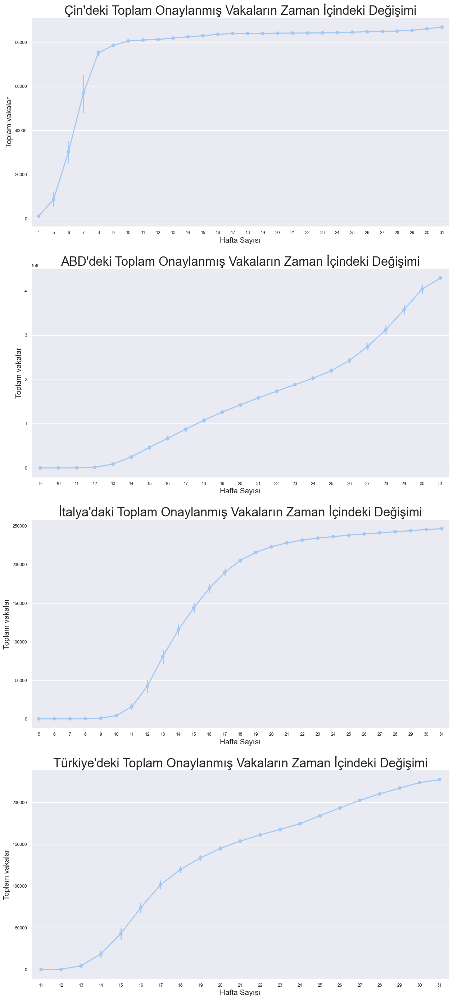

In [52]:
plt.figure(figsize=(15,30))

# Çin verisi
a = plt.subplot(4, 1, 1)
sns.pointplot(x=china.date.dt.isocalendar().week, y=china.confirmed)
plt.title("Çin'deki Toplam Onaylanmış Vakaların Zaman İçindeki Değişimi", fontsize=25)
plt.ylabel('Toplam vakalar', fontsize=15)
plt.xlabel('Hafta Sayısı', fontsize=15)

# ABD verisi
plt.subplot(4, 1, 2)
sns.pointplot(x=us.date.dt.isocalendar().week, y=us.confirmed)
plt.title("ABD'deki Toplam Onaylanmış Vakaların Zaman İçindeki Değişimi", fontsize=25)
plt.ylabel('Toplam vakalar', fontsize=15)
plt.xlabel('Hafta Sayısı', fontsize=15)

# İtalya verisi
plt.subplot(4, 1, 3)
sns.pointplot(x=italy.date.dt.isocalendar().week, y=italy.confirmed)
plt.title("İtalya'daki Toplam Onaylanmış Vakaların Zaman İçindeki Değişimi", fontsize=25)
plt.ylabel('Toplam vakalar', fontsize=15)
plt.xlabel('Hafta Sayısı', fontsize=15)

# Türkiye verisi
plt.subplot(4, 1, 4)
sns.pointplot(x=turkey.date.dt.isocalendar().week, y=turkey.confirmed)
plt.title("Türkiye'deki Toplam Onaylanmış Vakaların Zaman İçindeki Değişimi", fontsize=25)
plt.ylabel('Toplam vakalar', fontsize=15)
plt.xlabel('Hafta Sayısı', fontsize=15)

plt.subplots_adjust(bottom=0.01, top=0.9)
plt.show()

##### Gözlemlerimiz:
##### 1)0. günden 15. güne kadar, Covid-19'un kaynağı olan Çin'de eğim çok yüksek,diğer ülkelerde ise eğim oldukça düşük.
##### 2)15. günden sonra, ABD'de vaka sayısında artış olmuş, ancak İtalya ve Türkiye'de hala yok.
##### 3)Ama ondan sonra, ABD ve İtalya'da vaka sayısında büyük bir artış var.
##### 4)Türkiye, virüsün yayılmasını kontrol altına almak ve vaka sayısını azaltmak konusunda iyi bir iş çıkarıyor gibi görünüyor. Ancak son zamanlarda vaka sayısında bir artış yaşanıyor!

## B.Mevcut Aktif Vaka Sayısı

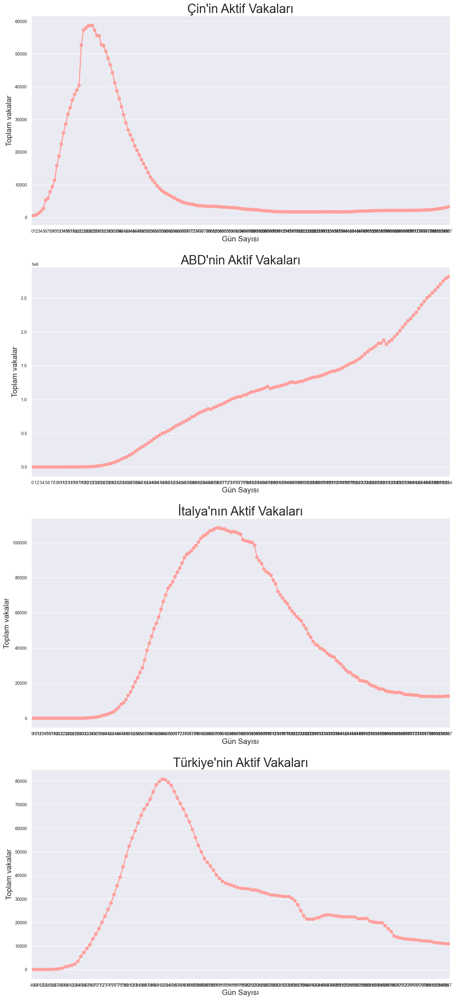

In [56]:
plt.figure(figsize=(15,30))

# Çin'in aktif vaka sayısının grafiği
plt.subplot(4, 1, 1)
sns.pointplot(x=china.index, y=china.active, color='r')
plt.title("Çin'in Aktif Vakaları", fontsize=25)
plt.xlabel('Gün Sayısı', fontsize=15)
plt.ylabel('Toplam vakalar', fontsize=15)

# ABD'nin aktif vaka sayısının grafiği
plt.subplot(4, 1, 2)
sns.pointplot(x=us.index, y=us.active, color='r')
plt.title("ABD'nin Aktif Vakaları", fontsize=25)
plt.xlabel('Gün Sayısı', fontsize=15)
plt.ylabel('Toplam vakalar', fontsize=15)

# İtalya'nın aktif vaka sayısının grafiği
plt.subplot(4, 1, 3)
sns.pointplot(x=italy.index, y=italy.active, color='r')
plt.title("İtalya'nın Aktif Vakaları", fontsize=25)
plt.xlabel('Gün Sayısı', fontsize=15)
plt.ylabel('Toplam vakalar', fontsize=15)

# Türkiye'nin aktif vaka sayısının grafiği
plt.subplot(4, 1, 4)
sns.pointplot(x=turkey.index, y=turkey.active, color='r')
plt.title("Türkiye'nin Aktif Vakaları", fontsize=25)
plt.xlabel('Gün Sayısı', fontsize=15)
plt.ylabel('Toplam vakalar', fontsize=15)

# Alt grafikler arasındaki boşluğu ayarlar
plt.subplots_adjust(bottom=0.01, top=0.9)

# Grafikleri göster
plt.show()

##### Gözlemlerimiz:
##### 1)Onaylanmış vakalardaki gözlemlerle aynı sonuçları veriyor.
##### 2)Tek fark, Çin'deki aktif vaka sayısının 30. günden itibaren artan bir şekilde azalması, çünkü Covid-19 virüsünü kontrol altına almayı başardılar.
##### 3)ABD,Türkiye ve İtalya'daki aktif vaka sayısı tehlikeli bir şekilde artıyor.

## C.Mevcut Ölüm Sayıları

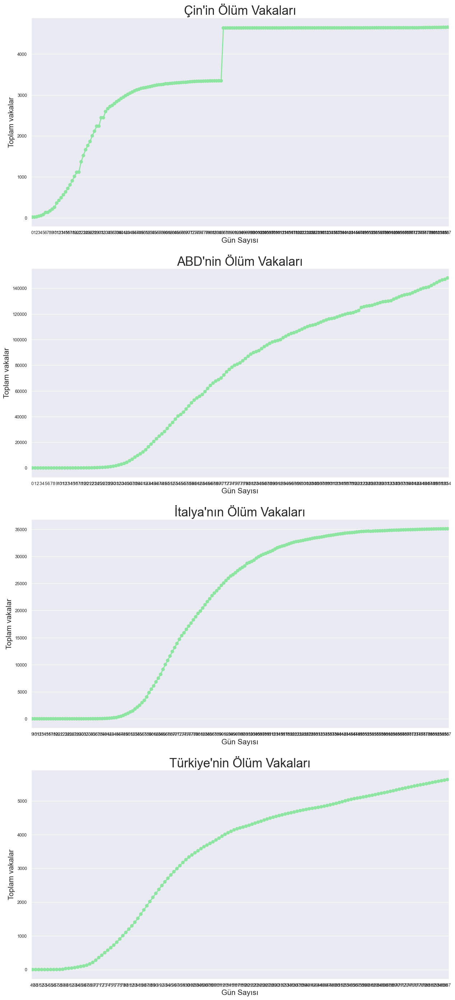

In [58]:
plt.figure(figsize=(15,30))

# Çin'in ölüm vakaları
plt.subplot(4, 1, 1)
sns.pointplot(x=china.index, y=china.deaths, color='g')
plt.title("Çin'in Ölüm Vakaları" , fontsize=25)
plt.xlabel('Gün Sayısı', fontsize=15)
plt.ylabel('Toplam vakalar', fontsize=15)

# ABD'nin ölüm vakaları
plt.subplot(4, 1, 2)
sns.pointplot(x=us.index, y=us.deaths, color='g')
plt.title("ABD'nin Ölüm Vakaları" , fontsize=25)
plt.xlabel('Gün Sayısı', fontsize=15)
plt.ylabel('Toplam vakalar', fontsize=15)

# İtalya'nın ölüm vakaları
plt.subplot(4, 1, 3)
sns.pointplot(x=italy.index, y=italy.deaths, color='g')
plt.title("İtalya'nın Ölüm Vakaları" , fontsize=25)
plt.xlabel('Gün Sayısı', fontsize=15)
plt.ylabel('Toplam vakalar', fontsize=15)

# Türkiye'nin ölüm vakaları
plt.subplot(4, 1, 4)
sns.pointplot(x=turkey.index, y=turkey.deaths, color='g')
plt.title("Türkiye'nin Ölüm Vakaları" , fontsize=25)
plt.xlabel('Gün Sayısı', fontsize=15)
plt.ylabel('Toplam vakalar', fontsize=15)

plt.subplots_adjust(bottom=0.01, top=0.9)
plt.show()

##### Gözlemlerimiz:
##### 1)Virüsün ilk ortaya çıktığı Çin, 30. günün sonrasında ölüm vakalarını önemli ölçüde azaltmayı başarmış.
##### 2)Ancak son zamanla İtalya'da ölüm vakalarında büyük bir artış yaşanmış.
##### 3)Türkiye ve ABD'de de ölüm vakalarında hafif bir artış gözlemlenmektedir.

## D.Mevcut İyileşen Sayısı

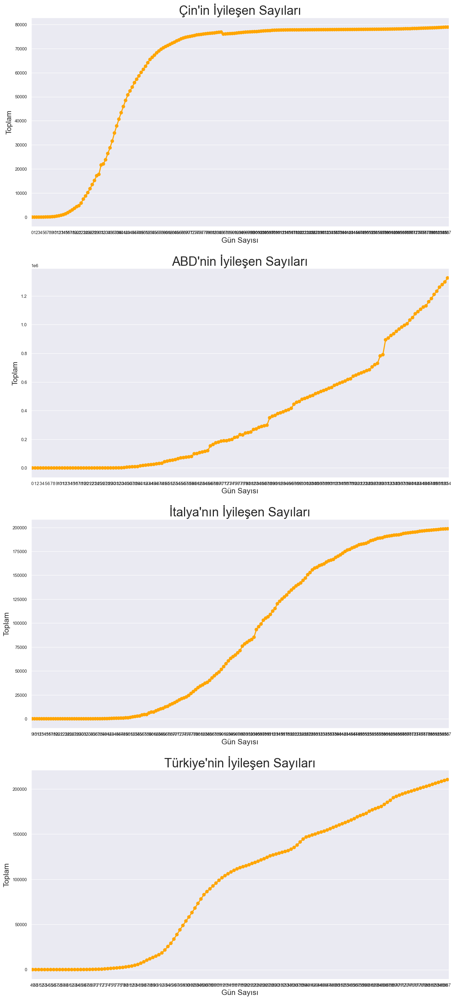

In [61]:
plt.figure(figsize=(15,30))

# Çin'in iyileşen vakaları
plt.subplot(4, 1, 1)
sns.pointplot(x=china.index, y=china.recovered, color='orange')
plt.title("Çin'in İyileşen Sayıları", fontsize=25)
plt.xlabel('Gün Sayısı', fontsize=15)
plt.ylabel('Toplam', fontsize=15)

# ABD'nin iyileşen vakaları
plt.subplot(4, 1, 2)
sns.pointplot(x=us.index, y=us.recovered, color='orange')
plt.title("ABD'nin İyileşen Sayıları", fontsize=25)
plt.xlabel('Gün Sayısı', fontsize=15)
plt.ylabel('Toplam', fontsize=15)

# İtalya'nın iyileşen vakaları
plt.subplot(4, 1, 3)
sns.pointplot(x=italy.index, y=italy.recovered, color='orange')
plt.title("İtalya'nın İyileşen Sayıları", fontsize=25)
plt.xlabel('Gün Sayısı', fontsize=15)
plt.ylabel('Toplam', fontsize=15)

# Türkiye'nin iyileşen vakaları
plt.subplot(4, 1, 4)
sns.pointplot(x=turkey.index, y=turkey.recovered, color='orange')
plt.title("Türkiye'nin İyileşen Sayıları", fontsize=25)
plt.xlabel('Gün Sayısı', fontsize=15)
plt.ylabel('Toplam', fontsize=15)

plt.subplots_adjust(bottom=0.01, top=0.9)
plt.show()

##### Gözlemlerimiz:
##### 1)Onaylanmış vaka sayısının oldukça fazla olmasına rağmen Çin birçok hastayı iyileştirmeyi başarmıştır.
##### 2)İtalya da iyileşen hasta sayısı artış gösteriyor, ancak son zamanlarda ölüm sayıları da çok fazla artmıştır.
##### 3)ABD ve Türkiye'deki iyileşme sayıları da azdır.

###### Hasret İşler(220710017)-Defne Gödelekoğlu(220710071)